# 🎨 Proyecto Final Guiado: Análisis Perceptual y Limpieza de Datos en el Espacio de Color
### Introducción a Python para Ciencia de Datos e Inteligencia Artificial
---

## 🎯 Contexto del Proyecto

En este proyecto final trabajarás con los datos reales recopilados a través de la plataforma web del juego de mesa **Hues and Cues**, publicado en la investigación científica sobre percepción cromática humana e Inteligencia Artificial (*Alabau-Bosque et al.*).

En el juego, los participantes ven una palabra (por ejemplo: `"MANZANA"`, `"FLAMENCO"`, `"ESPERANZA"`, `"TRACTOR"`) y deben seleccionar una casilla del tablero (una cuadrícula de 480 tonos de color con coordenadas de la `A1` a la `P30`) que mejor represente el concepto visual de dicha palabra.

### 🎯 Objetivos de Aprendizaje:
1. **Manejo de Colecciones y Mapeos:** Uso intensivo de **diccionarios** (`dict`) para traducción de categorías y mapeo de casillas del tablero a nombres cromáticos (`.map()`).
2. **Creación de Funciones Modulares:** Definición de funciones reutilizables con parámetros, retorno y documentación (`def`, `return`, *docstrings*).
3. **Análisis Demográfico y Limpieza de Datos con Pandas:** Exploración de datos, cálculo de frecuencias relativas y filtrado estricto de participantes con **Daltonismo (Deficiencia de Visión Cromática - CVD)** siguiendo la metodología de calidad del artículo científico (Secciones 2.2 y 2.3 de `HuesAndCues.pdf`).
4. **Análisis de Percepción e Hipótesis Culturales:** Estudio comparativo de discrepancias cromáticas en personas daltónicas frente a tricrómatas, y evaluación del fenómeno de las **"anclas culturales"** (*TRACTOR* y *ESPERANZA*).
5. **Visualización de Datos con Seaborn y Matplotlib:** Creación de dashboards demográficos multivariable (`plt.subplots`), gráficos categóricos de barras (`sns.countplot`, `sns.barplot`) y gráficos de consenso ordenados.

## ⚙️ Fase 0: Configuración del Entorno y Librerías

Importaremos las librerías fundamentales de análisis de datos y visualización:
- `pandas` (`pd`): Manipulación tabular y operaciones sobre DataFrames.
- `numpy` (`np`): Soporte numérico y operaciones vectorizadas.
- `matplotlib.pyplot` (`plt`) y `seaborn` (`sns`): Creación de gráficos estadísticos y estéticos.

In [1]:
# Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética global
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✅ Librerías importadas y entorno configurado correctamente.")

✅ Librerías importadas y entorno configurado correctamente.


---
## 📥 Fase 1: Ingesta, Exploración y Diccionarios (EDA)

### 1.1 Carga de los Archivos de Datos
Debes cargar dos archivos fundamentales ubicados en el directorio del proyecto:
1. `HC.csv`: Contiene las 3.899 respuestas de los participantes humanos. Cárgalo en un DataFrame llamado `df_humanos`.
2. `board_color_categories.txt`: Mapea cada una de las 480 casillas del tablero a su color semántico básico (`brown`, `red`, `orange`, `yellow`, `green`, `blue`, `purple`, `pink`). Cárgalo en un DataFrame llamado `df_tablero`.

> 💡 **Pistas:**
> - El archivo `board_color_categories.txt` está separado por comas `,` y **no contiene cabecera**. Utiliza `header=None` y asigna nombres a las columnas: `names=['coordinate', 'color']`.
> - Revisa las dimensiones (`.shape`) y las primeras filas (`.head()`) de cada DataFrame.

In [2]:
# TODO 1.1: Cargar los dos archivos de datos
df_humanos = pd.read_csv('HC.csv')
df_tablero = pd.read_csv('board_color_categories.txt', sep=',', header=None,
                         names=['coordinate', 'color'])

print("df_humanos:", df_humanos.shape)
display(df_humanos.head())
print("df_tablero:", df_tablero.shape)
display(df_tablero.head())

df_humanos: (3899, 10)


,userId,timestamp,clueCategory,clueId,word,coordinate,language,gender,ageRange,colorblind
0,4ae551a8-0d2b-4b34-ab64-8e6721cbe470,2025-07-15T17:14:02.825Z,ANIMAL,1,SALMÓN,E11,spanish,female,20-29,no
1,4ae551a8-0d2b-4b34-ab64-8e6721cbe470,2025-07-15T17:14:41.330Z,ANIMAL,2,BALLENA,K26,spanish,female,20-29,no
2,4ae551a8-0d2b-4b34-ab64-8e6721cbe470,2025-07-15T17:14:48.713Z,ANIMAL,3,PARDO,C2,spanish,female,20-29,no
3,4ae551a8-0d2b-4b34-ab64-8e6721cbe470,2025-07-15T17:15:21.721Z,ANIMAL,4,FLAMENCO,C15,spanish,female,20-29,no
4,4ae551a8-0d2b-4b34-ab64-8e6721cbe470,2025-07-15T17:15:31.790Z,ANIMAL,5,ZORRO,C7,spanish,female,20-29,no


df_tablero: (480, 2)


,coordinate,color
0,A1,brown
1,A2,brown
2,A3,brown
3,A4,brown
4,A5,brown


### 1.2 Inspección de Tipos de Datos y Valores Faltantes
Comprueba si existen valores nulos en `df_humanos` con `.isnull().sum()` y muestra el resumen de columnas y tipos de datos con `.info()`.

In [3]:
# TODO 1.2: Inspeccionar tipos de datos y valores nulos en df_humanos
print("Valores nulos por columna:")
print(df_humanos.isnull().sum())
print()
df_humanos.info()

Valores nulos por columna:
userId          0
timestamp       0
clueCategory    0
clueId          0
word            0
coordinate      0
language        0
gender          0
ageRange        0
colorblind      0
dtype: int64

<class 'pandas.DataFrame'>
RangeIndex: 3899 entries, 0 to 3898
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   userId        3899 non-null   str  
 1   timestamp     3899 non-null   str  
 2   clueCategory  3899 non-null   str  
 3   clueId        3899 non-null   int64
 4   word          3899 non-null   str  
 5   coordinate    3899 non-null   str  
 6   language      3899 non-null   str  
 7   gender        3899 non-null   str  
 8   ageRange      3899 non-null   str  
 9   colorblind    3899 non-null   str  
dtypes: int64(1), str(9)
memory usage: 304.7 KB


### 1.3 Normalización de Categorías Semánticas con Diccionarios
Observa los valores únicos en `df_humanos['clueCategory']`. En el dataset original conviven etiquetas en inglés (`FOOD`, `STONE`, `ENVIRONMENT`, `SUBJETIVE`, `PLANT`) y en español (`COMESTIBLE`, `PIEDRA`, `ENTORNO`, `SUBJETIVO`, `PLANTA`).

1. Define un diccionario en Python llamado `traduccion_cat` que traduzca las etiquetas en inglés a su equivalente estándar en español:
   - `'FOOD'` $\rightarrow$ `'COMESTIBLE'`
   - `'STONE'` $\rightarrow$ `'PIEDRA'`
   - `'ENVIRONMENT'` $\rightarrow$ `'ENTORNO'`
   - `'SUBJETIVE'` $\rightarrow$ `'SUBJETIVO'`
   - `'PLANT'` $\rightarrow$ `'PLANTA'`
2. Aplica este diccionario a la columna `df_humanos['clueCategory']` usando el método `.replace(traduccion_cat)`.
3. Muestra el recuento final de cada categoría con `.value_counts()`.

In [4]:
# TODO 1.3: Crear el diccionario de traducción y normalizar df_humanos['clueCategory']
print("Valores únicos originales:", sorted(df_humanos['clueCategory'].unique()))

traduccion_cat = {
    'FOOD': 'COMESTIBLE',
    'STONE': 'PIEDRA',
    'ENVIRONMENT': 'ENTORNO',
    'SUBJETIVE': 'SUBJETIVO',
    'PLANT': 'PLANTA',
}

df_humanos['clueCategory'] = df_humanos['clueCategory'].replace(traduccion_cat)

print("\nRecuento final por categoría:")
print(df_humanos['clueCategory'].value_counts())

Valores únicos originales: ['ANIMAL', 'COMESTIBLE', 'ENTORNO', 'ENVIRONMENT', 'FOOD', 'PIEDRA', 'PLANT', 'PLANTA', 'POP', 'STONE', 'SUBJETIVE', 'SUBJETIVO']

Recuento final por categoría:
clueCategory
SUBJETIVO     567
POP           567
ENTORNO       566
COMESTIBLE    562
ANIMAL        549
PIEDRA        547
PLANTA        541
Name: count, dtype: int64


### 1.4 Mapeo de Casilla a Color Semántico mediante Diccionarios
Para poder analizar qué color eligió cada participante (por ejemplo, si eligió un tono `pink`, `green`, `blue`, etc.), debemos enriquecer `df_humanos` con la información del tablero.

1. Crea un diccionario rápido `coord_a_color` a partir de `df_tablero` combinando las columnas `'coordinate'` y `'color'` usando `dict(zip(...))`.
2. Crea una nueva columna en `df_humanos` llamada `'color'` mapeando la columna `'coordinate'` con el diccionario creado (`df_humanos['coordinate'].map(coord_a_color)`).
3. Muestra las primeras 5 filas con las columnas `['clueId', 'word', 'clueCategory', 'coordinate', 'color']`.

In [5]:
# TODO 1.4: Crear el diccionario coord_a_color y enriquecer df_humanos
coord_a_color = dict(zip(df_tablero['coordinate'], df_tablero['color']))
print("Casillas en el diccionario:", len(coord_a_color))

df_humanos['color'] = df_humanos['coordinate'].map(coord_a_color)

# Comprobación: ninguna coordenada debería quedarse sin color
print("Coordenadas sin color asignado:", df_humanos['color'].isnull().sum())

display(df_humanos[['clueId', 'word', 'clueCategory', 'coordinate', 'color']].head(5))

Casillas en el diccionario: 480
Coordenadas sin color asignado: 0


,clueId,word,clueCategory,coordinate,color
0,1,SALMÓN,ANIMAL,E11,pink
1,2,BALLENA,ANIMAL,K26,blue
2,3,PARDO,ANIMAL,C2,brown
3,4,FLAMENCO,ANIMAL,C15,pink
4,5,ZORRO,ANIMAL,C7,red


In [6]:
# Paleta con el color real de cada categoría: se reutiliza en las tablas y en los gráficos
paleta_colores = {'brown': '#8B5A2B', 'red': '#D62728', 'orange': '#FF8C00', 'yellow': '#F2C500',
                  'green': '#2CA02C', 'blue': '#1F77B4', 'purple': '#7B3FA0', 'pink': '#F06EAA'}
orden_colores = list(paleta_colores.keys())
COLORES_CLAROS = {'yellow', 'orange', 'pink'}   # sobre estos fondos el texto se lee mejor en negro


def pintar_color(valor):
    """Estilo CSS que pinta una celda con el color que nombra (p. ej. 'green')."""
    if valor not in paleta_colores:
        return ''
    texto = 'black' if valor in COLORES_CLAROS else 'white'
    return f'background-color: {paleta_colores[valor]}; color: {texto}; font-weight: bold'


def pintar_booleano(valor):
    """Verde si es True, rojo si es False."""
    return ('background-color: #d4edda; color: #155724' if valor
            else 'background-color: #f8d7da; color: #721c24')


# Vista previa: la muestra anterior con la columna 'color' pintada
display(df_humanos[['clueId', 'word', 'clueCategory', 'coordinate', 'color']].head(8)
        .style.map(pintar_color, subset=['color']))

,clueId,word,clueCategory,coordinate,color
0,1,SALMÓN,ANIMAL,E11,pink
1,2,BALLENA,ANIMAL,K26,blue
2,3,PARDO,ANIMAL,C2,brown
3,4,FLAMENCO,ANIMAL,C15,pink
4,5,ZORRO,ANIMAL,C7,red
5,6,GRILLO,ANIMAL,D4,orange
6,7,CANARIO,ANIMAL,G2,yellow
7,8,CERDO,ANIMAL,D15,pink


---
## 👥 Fase 2: Perfil Demográfico y Filtrado de Participantes
> *Basado en las Secciones 2.2 y 2.3 del artículo científico (HuesAndCues.pdf)*

### 2.1 Análisis Demográfico de la Cohorte de Participantes
En `df_humanos`, cada fila representa la respuesta a una palabra individual. Sin embargo, cada participante respondió a una serie de 15 palabras.

1. Extrae los participantes únicos eliminando duplicados por la columna `'userId'` con `.drop_duplicates(subset=['userId'])` y guarda el resultado en un nuevo DataFrame llamado `df_usuarios`.
2. ¿Cuántos participantes únicos participaron en el experimento? (Usa `len(df_usuarios)` o `df_humanos['userId'].nunique()`).
3. Muestra la distribución de los participantes por:
   - **Género** (`df_usuarios['gender'].value_counts()`)
   - **Rango de Edad** (`df_usuarios['ageRange'].value_counts()`)
   - **Idioma** (`df_usuarios['language'].value_counts()`)
   - **Condición Visual / Daltonismo** (`df_usuarios['colorblind'].value_counts()` y en porcentaje con `normalize=True`)

In [7]:
# TODO 2.1: Crear df_usuarios y calcular los descriptores demográficos
df_usuarios = df_humanos.drop_duplicates(subset=['userId'])

print("Participantes únicos:", len(df_usuarios))
print("Comprobación con nunique():", df_humanos['userId'].nunique())

print("\n--- Género ---")
print(df_usuarios['gender'].value_counts())
print("\n--- Rango de edad ---")
print(df_usuarios['ageRange'].value_counts())
print("\n--- Idioma ---")
print(df_usuarios['language'].value_counts())
print("\n--- Daltonismo (recuento) ---")
print(df_usuarios['colorblind'].value_counts())
print("\n--- Daltonismo (%) ---")
print((df_usuarios['colorblind'].value_counts(normalize=True) * 100).round(2))

Participantes únicos: 324
Comprobación con nunique(): 324

--- Género ---
gender
male                 190
female               120
prefer-not-to-say     10
other                  4
Name: count, dtype: int64

--- Rango de edad ---
ageRange
20-29    130
10-19    128
30-39     32
50-59     12
40-49     10
60-69      6
70         4
-10        2
Name: count, dtype: int64

--- Idioma ---
language
spanish    303
english     21
Name: count, dtype: int64

--- Daltonismo (recuento) ---
colorblind
no     320
YES      4
Name: count, dtype: int64

--- Daltonismo (%) ---
colorblind
no     98.77
YES     1.23
Name: proportion, dtype: float64


### 2.2 Filtrado de Calidad: Exclusión de Participantes con Daltonismo (CVD)
Tal y como explica el artículo en la **Sección 2.3**:
> *"To guarantee the integrity of the perceptual ground truth, we applied a strict filtering criterion based on self-reported visual capabilities, excluding participants who reported Color Vision Deficiency (CVD)..."*

1. Define una función llamada `filtrar_participantes(df, condicion_daltonismo='no')` con su correspondiente *docstring* que reciba un DataFrame y filtre las filas según la columna `'colorblind'`.
2. Utiliza tu función para crear dos DataFrames:
   - `df_tricromatas`: Participantes con visión normal (`colorblind == 'no'`). Esta será nuestra **verdad de referencia (ground truth)** para el resto del estudio.
   - `df_daltonicos`: Participantes que declararon daltonismo (`colorblind == 'YES'`).
3. Imprime cuántas respuestas totales contiene cada grupo y cuántos usuarios únicos representa cada uno.

In [8]:
# TODO 2.2: Implementar función de filtrado y segmentar df_humanos
def filtrar_participantes(df, condicion_daltonismo='no'):
    """
    Filtra el DataFrame según la condición visual declarada en la columna 'colorblind'.

    Parámetros:
        df (pd.DataFrame): DataFrame con la columna 'colorblind'.
        condicion_daltonismo (str): 'no' para tricrómatas o 'YES' para daltónicos.

    Retorna:
        pd.DataFrame: DataFrame filtrado.
    """
    return df[df['colorblind'] == condicion_daltonismo].copy()

# Crear df_tricromatas y df_daltonicos
df_tricromatas = filtrar_participantes(df_humanos, 'no')
df_daltonicos = filtrar_participantes(df_humanos, 'YES')

for nombre, grupo in [('Tricrómatas', df_tricromatas), ('Daltónicos', df_daltonicos)]:
    print(f"{nombre}: {len(grupo)} respuestas de {grupo['userId'].nunique()} usuarios únicos")

# ⚠️ Control de calidad: la etiqueta 'colorblind' está registrada por RESPUESTA, no por usuario.
# Algunos usuarios tienen respuestas marcadas con 'no' y con 'YES', por eso 323 + 9 > 324.
# Filtrar por fila (como hace el paper) reproduce las 3.870 respuestas tricrómatas de referencia.
etiquetas_por_usuario = df_humanos.groupby('userId')['colorblind'].nunique()
usuarios_mixtos = etiquetas_por_usuario[etiquetas_por_usuario > 1].index
print(f"\nUsuarios con etiqueta 'colorblind' inconsistente entre respuestas: {len(usuarios_mixtos)}")
print("Usuarios que solo aparecen en el grupo daltónico:",
      df_daltonicos.loc[~df_daltonicos['userId'].isin(usuarios_mixtos), 'userId'].nunique())

Tricrómatas: 3870 respuestas de 323 usuarios únicos
Daltónicos: 29 respuestas de 9 usuarios únicos

Usuarios con etiqueta 'colorblind' inconsistente entre respuestas: 8
Usuarios que solo aparecen en el grupo daltónico: 1


---
## 👁️ Fase 3: Estudio del Impacto del Daltonismo en la Percepción Cromática
> *Basado en la Sección 2.3 y Figura 4 del artículo científico*

### 3.1 Función de Comparación de Percepción Cromática por Palabra
Vamos a crear una función que nos permita contrastar qué color perciben los observadores con visión tricromática normal frente a los observadores con daltonismo para cualquier palabra.

1. Define una función `comparar_percepcion_palabra(palabra, df_tri, df_dal)` que:
   - Extraiga las respuestas de `df_tri` y de `df_dal` para la palabra indicada.
   - Calcule el color más votado (*moda*) en el grupo de tricrómatas y en el grupo de daltónicos.
   - Devuelva un diccionario o imprima un resumen con:
     - `palabra`
     - `color_tricromatas` (color mayoritario y porcentaje de consenso)
     - `color_daltonicos` (colores elegidos por los daltónicos)
     - `coincidencia` (`True` si el color más votado coincide en ambos grupos, `False` en caso contrario).

In [9]:
# TODO 3.1: Definir la función comparar_percepcion_palabra
def comparar_percepcion_palabra(palabra, df_tri, df_dal):
    """
    Compara las elecciones de color entre observadores tricrómatas y daltónicos para una palabra.

    Parámetros:
        palabra (str): palabra (pista) a analizar, p. ej. 'CIELO'.
        df_tri (pd.DataFrame): respuestas de tricrómatas (con columnas 'word' y 'color').
        df_dal (pd.DataFrame): respuestas de daltónicos (con columnas 'word' y 'color').

    Retorna:
        dict: palabra, color modal de tricrómatas y su % de consenso, colores elegidos
              por los daltónicos, color modal de daltónicos y si coinciden ambas modas.
              Devuelve None si la palabra no tiene respuestas en alguno de los grupos.
    """
    colores_tri = df_tri.loc[df_tri['word'] == palabra, 'color']
    colores_dal = df_dal.loc[df_dal['word'] == palabra, 'color']

    if colores_tri.empty or colores_dal.empty:
        print(f"⚠️ '{palabra}' no tiene respuestas en alguno de los dos grupos.")
        return None

    frec_tri = colores_tri.value_counts(normalize=True) * 100
    moda_tri = frec_tri.index[0]
    moda_dal = colores_dal.value_counts().index[0]

    return {
        'palabra': palabra,
        'color_tricromatas': moda_tri,
        'consenso_tricromatas_%': round(frec_tri.iloc[0], 1),
        'n_tricromatas': len(colores_tri),
        'color_daltonicos': ', '.join(colores_dal.tolist()),
        'moda_daltonicos': moda_dal,
        'n_daltonicos': len(colores_dal),
        'coincidencia': moda_tri == moda_dal,
    }

# Prueba la función con 'CIELO' y con 'ZAFIRO'
for p in ['CIELO', 'ZAFIRO']:
    print(comparar_percepcion_palabra(p, df_tricromatas, df_daltonicos))

{'palabra': 'CIELO', 'color_tricromatas': 'blue', 'consenso_tricromatas_%': np.float64(97.7), 'n_tricromatas': 44, 'color_daltonicos': 'blue', 'moda_daltonicos': 'blue', 'n_daltonicos': 1, 'coincidencia': True}
{'palabra': 'ZAFIRO', 'color_tricromatas': 'blue', 'consenso_tricromatas_%': np.float64(71.8), 'n_tricromatas': 39, 'color_daltonicos': 'brown', 'moda_daltonicos': 'brown', 'n_daltonicos': 1, 'coincidencia': False}


### 3.2 Detección de Discrepancias y Confusión Espectral
El daltonismo suele afectar de manera muy pronunciada a la discriminación de tonos en el espectro **rojo-verde** o en tonos saturados con matices marrones/azules.

1. Itera sobre una lista de palabras presentes en el grupo de daltónicos (por ejemplo: `['ZAFIRO', 'JADE', 'MALVA', 'BLAS (Y EPI)', 'HURACÁN', 'CIELO', 'BARBIE', 'MENTA']`).
2. Ejecuta `comparar_percepcion_palabra()` para cada una y muestra los resultados.
3. Construye una tabla cruzada (`pd.crosstab`) con las elecciones de color de los daltónicos para observar qué colores eligen con mayor frecuencia.

In [10]:
# TODO 3.2: Comparar la lista de palabras y construir la tabla de discrepancias
palabras_estudio = ['ZAFIRO', 'JADE', 'MALVA', 'BLAS (Y EPI)', 'HURACÁN', 'CIELO', 'BARBIE', 'MENTA']

resultados = []
for palabra in palabras_estudio:
    res = comparar_percepcion_palabra(palabra, df_tricromatas, df_daltonicos)
    if res is not None:
        resultados.append(res)

df_comparacion = pd.DataFrame(resultados)
display(df_comparacion.style
        .map(pintar_color, subset=['color_tricromatas', 'moda_daltonicos'])
        .map(pintar_booleano, subset=['coincidencia'])
        .bar(subset=['consenso_tricromatas_%'], color='#9ecae1', vmin=0, vmax=100)
        .format({'consenso_tricromatas_%': '{:.1f}'})
        .hide(axis='index'))
print(f"Coincidencias: {df_comparacion['coincidencia'].sum()} de {len(df_comparacion)} palabras")

# Tabla cruzada: palabra x color elegido por los daltónicos (todas sus respuestas)
tabla_daltonicos = pd.crosstab(df_daltonicos['word'], df_daltonicos['color'],
                               margins=True, margins_name='TOTAL')
celdas_sin_total = pd.IndexSlice[tabla_daltonicos.index.drop('TOTAL'),
                                 tabla_daltonicos.columns.drop('TOTAL')]
display(tabla_daltonicos.style
        .background_gradient(cmap='Greys', subset=celdas_sin_total)
        .map_index(pintar_color, axis='columns'))

# Tabla cruzada: color modal tricrómata (verdad de referencia) vs. color elegido por el daltónico
modas_tri = df_tricromatas.groupby('word')['color'].agg(lambda s: s.value_counts().index[0])
df_dal_cmp = df_daltonicos.assign(color_referencia=df_daltonicos['word'].map(modas_tri))
# La diagonal son los aciertos; fuera de ella, las confusiones
display(pd.crosstab(df_dal_cmp['color_referencia'], df_dal_cmp['color'],
                    rownames=['Moda tricrómata'], colnames=['Elección daltónica'])
        .style.background_gradient(cmap='Blues', axis=None)
        .map_index(pintar_color, axis='index')
        .map_index(pintar_color, axis='columns'))

palabra,color_tricromatas,consenso_tricromatas_%,n_tricromatas,color_daltonicos,moda_daltonicos,n_daltonicos,coincidencia
ZAFIRO,blue,71.8,39,brown,brown,1,False
JADE,green,60.4,53,blue,blue,1,False
MALVA,pink,33.3,48,brown,brown,1,False
BLAS (Y EPI),yellow,59.3,27,red,red,1,False
HURACÁN,blue,69.0,29,pink,pink,1,False
CIELO,blue,97.7,44,blue,blue,1,True
BARBIE,pink,100.0,32,pink,pink,1,True
MENTA,green,90.4,52,green,green,1,True


Coincidencias: 3 de 8 palabras


color,blue,brown,green,orange,pink,purple,red,yellow,TOTAL
word,,,,,,,,,
AXOLOTE,0,0,0,0,1,0,0,0,1
BARBIE,0,0,0,0,1,0,0,0,1
BLAS (Y EPI),0,0,0,0,0,0,1,0,1
BRUJERÍA,0,1,0,0,0,1,0,0,2
CIELO,1,0,0,0,0,0,0,0,1
EPI (Y BLAS),0,0,0,1,0,0,0,0,1
ESMERALDA,1,0,1,0,0,0,0,0,2
HUEVO,1,0,0,0,0,0,0,0,1
HURACÁN,0,0,0,0,1,0,0,0,1


Elección daltónica,blue,brown,green,orange,pink,purple,red,yellow
Moda tricrómata,,,,,,,,
blue,3,1,0,0,1,0,0,0
brown,0,1,0,0,0,0,0,0
green,2,0,4,0,0,0,0,0
orange,1,0,0,2,0,0,1,1
pink,0,1,0,0,2,0,0,0
purple,0,1,0,0,0,1,0,0
red,0,0,0,0,0,0,6,0
yellow,0,0,0,0,0,0,1,0


---
## 🏛️ Fase 4: Anclas Culturales y Consenso Semántico
> *Basado en la Sección 2.2 y Figura 6 del artículo científico*

### 4.1 Análisis de Anclas Culturales (*TRACTOR* y *ESPERANZA*)
En el estudio se introdujeron palabras diseñadas como **"anclas culturales"** para comprobar si la memoria visual responde a la realidad física de los objetos o al imaginario cultural y lingüístico de la población:

1. **El caso de `TRACTOR`:** En el mundo físico agrícola, los tractores suelen ser de color **verde** (ej. John Deere) o **rojo** (ej. Massey Ferguson). Sin embargo, en la cultura popular hispanohablante existe una canción icónica (*"Mi tractor amarillo"*).
   - Filtra `df_tricromatas` para la palabra `'TRACTOR'`.
   - Calcula la distribución porcentual de los colores elegidos (`.value_counts(normalize=True) * 100`).
   - ¿Qué porcentaje eligió amarillo frente a verde o rojo?

2. **El caso de `ESPERANZA`:** Las emociones y conceptos abstractos no tienen un color físico real. Sin embargo, en español existe la metáfora arraigada del *"verde esperanza"*.
   - Filtra `df_tricromatas` para la palabra `'ESPERANZA'`.
   - Calcula la distribución porcentual de los colores elegidos.

In [11]:
# TODO 4.1: Analizar las anclas culturales TRACTOR y ESPERANZA
def distribucion_colores(df, palabra):
    """Devuelve la distribución porcentual (%) de colores elegidos para una palabra."""
    return (df.loc[df['word'] == palabra, 'color'].value_counts(normalize=True) * 100).round(1)

dist_tractor = distribucion_colores(df_tricromatas, 'TRACTOR')
print(f"TRACTOR (n={(df_tricromatas['word'] == 'TRACTOR').sum()}) — distribución (%):")
print(dist_tractor)
print(f"\n→ Amarillo: {dist_tractor.get('yellow', 0):.1f}% | "
      f"Verde: {dist_tractor.get('green', 0):.1f}% | Rojo: {dist_tractor.get('red', 0):.1f}%")

dist_esperanza = distribucion_colores(df_tricromatas, 'ESPERANZA')
print(f"\nESPERANZA (n={(df_tricromatas['word'] == 'ESPERANZA').sum()}) — distribución (%):")
print(dist_esperanza)
print(f"\n→ Verde: {dist_esperanza.get('green', 0):.1f}%")

TRACTOR (n=25) — distribución (%):
color
yellow    64.0
green     16.0
red        8.0
brown      8.0
orange     4.0
Name: proportion, dtype: float64

→ Amarillo: 64.0% | Verde: 16.0% | Rojo: 8.0%

ESPERANZA (n=36) — distribución (%):
color
green     80.6
blue      11.1
purple     2.8
yellow     2.8
red        2.8
Name: proportion, dtype: float64

→ Verde: 80.6%


### 4.2 Consenso Semántico por Categoría
¿Qué categorías de conceptos generan mayor acuerdo entre los humanos (consenso alto) y cuáles presentan mayor dispersión o subjetividad (consenso bajo)?

1. Define una función `calcular_consenso(serie_colores)` que reciba una serie de colores elegidos para una palabra y calcule el **porcentaje de votos que obtuvo el color mayoritario**:
   $$\text{Consenso (\%)} = \frac{\text{votos del color más repetido}}{\text{total de votos de la palabra}} \times 100$$
2. Agrupa `df_tricromatas` por `['clueCategory', 'word']` y calcula el consenso para cada palabra aplicando tu función con `.apply()` o agregaciones.
3. Agrupa por `'clueCategory'` para obtener el **consenso medio de cada categoría** y ordénalo de mayor a menor con `.sort_values(ascending=False)`.

In [12]:
# TODO 4.2: Función calcular_consenso y agregación por categoría semántica
def calcular_consenso(serie_colores):
    """
    Calcula el porcentaje de acuerdo en torno al color modal (más votado).

    Parámetros:
        serie_colores (pd.Series): colores elegidos para una misma palabra.

    Retorna:
        float: % de votos del color mayoritario sobre el total de votos.
    """
    if len(serie_colores) == 0:
        return np.nan
    return serie_colores.value_counts().iloc[0] / len(serie_colores) * 100

# Calcular consenso por palabra y promedio por categoría
consenso_palabra = (df_tricromatas.groupby(['clueCategory', 'word'])['color']
                    .agg(consenso=calcular_consenso, n_votos='size')
                    .reset_index())

# ⚠️ Las palabras en inglés (FOX, APPLE...) tienen muy pocos votos (1-3) y obtienen un consenso
# artificial del 100%. Para que la media por categoría sea robusta exigimos un mínimo de votos.
MIN_VOTOS = 10
consenso_fiable = consenso_palabra[consenso_palabra['n_votos'] >= MIN_VOTOS]
print(f"Palabras totales: {len(consenso_palabra)} | con >= {MIN_VOTOS} votos: {len(consenso_fiable)}")

def estilo_consenso(df):
    """Barra proporcional al % de consenso (0-100)."""
    return (df.style.bar(subset=['consenso'], color='#74c476', vmin=0, vmax=100)
            .format({'consenso': '{:.1f}'}).hide(axis='index'))

print("\nPalabras con mayor consenso:")
display(estilo_consenso(consenso_fiable.sort_values('consenso', ascending=False).head(10)))
print("Palabras con menor consenso:")
display(estilo_consenso(consenso_fiable.sort_values('consenso').head(10)))

consenso_categoria = (consenso_fiable.groupby('clueCategory')['consenso']
                      .mean()
                      .sort_values(ascending=False))
consenso_sin_filtro = consenso_palabra.groupby('clueCategory')['consenso'].mean()

print(f"Consenso medio por categoría (%), palabras con >= {MIN_VOTOS} votos:")
print(consenso_categoria.round(1))
print("\nComparación con la media sin filtrar (incluye palabras con 1-3 votos):")
display(pd.DataFrame({'con_filtro': consenso_categoria,
                      'sin_filtro': consenso_sin_filtro})
        .style.background_gradient(cmap='RdYlGn', vmin=0, vmax=100, axis=None)
        .format('{:.1f}'))

Palabras totales: 177 | con >= 10 votos: 100

Palabras con mayor consenso:


clueCategory,word,consenso,n_votos
COMESTIBLE,PEPINO,100.0,39
ENTORNO,CÉSPED,100.0,48
ANIMAL,RANA,100.0,46
ENTORNO,MUSGO,100.0,30
POP,HULK,100.0,25
POP,PETER PAN,100.0,26
POP,GRINCH,100.0,29
POP,SIMPSON,100.0,27
POP,SONIC,100.0,37
PLANTA,MADERA,100.0,46


Palabras con menor consenso:


clueCategory,word,consenso,n_votos
PLANTA,CLAVEL,32.8,58
PLANTA,MALVA,33.3,48
SUBJETIVO,VERGÜENZA,34.2,38
COMESTIBLE,REMOLACHA,37.0,27
ANIMAL,ZORRO,37.8,37
PIEDRA,TEJA,38.0,50
PLANTA,CORAL,38.5,52
ENTORNO,ARENA,41.3,46
POP,FLASH,42.9,21
SUBJETIVO,PRIMAVERA,45.2,31


Consenso medio por categoría (%), palabras con >= 10 votos:
clueCategory
POP           82.1
COMESTIBLE    78.1
ENTORNO       75.9
ANIMAL        74.0
SUBJETIVO     68.7
PLANTA        68.1
PIEDRA        66.6
Name: consenso, dtype: float64

Comparación con la media sin filtrar (incluye palabras con 1-3 votos):


,con_filtro,sin_filtro
clueCategory,,
ANIMAL,74.0,77.7
COMESTIBLE,78.1,79.5
ENTORNO,75.9,79.1
PIEDRA,66.6,71.0
PLANTA,68.1,77.6
POP,82.1,83.7
SUBJETIVO,68.7,73.6


---
## 📊 Fase 5: Visualización de Datos (DataViz con Matplotlib y Seaborn)

### 5.1 Gráfico 1: Dashboard Demográfico del Estudio (4 Subplots con `plt.subplots`)
Crea una figura con $2 \times 2$ subplots (`fig, axes = plt.subplots(2, 2, figsize=(15, 10))`) utilizando `df_usuarios`:
- **Subplot (0, 0):** Distribución por Rango de Edad (`sns.countplot` en `x='ageRange'`).
- **Subplot (0, 1):** Distribución por Género (`sns.countplot` en `x='gender'`).
- **Subplot (1, 0):** Distribución por Idioma (`sns.countplot` en `x='language'`).
- **Subplot (1, 1):** Condición Visual: Daltónicos vs. Tricrómatas (`sns.countplot` en `x='colorblind'`).

Personaliza títulos, etiquetas de ejes y utiliza `plt.tight_layout()`.

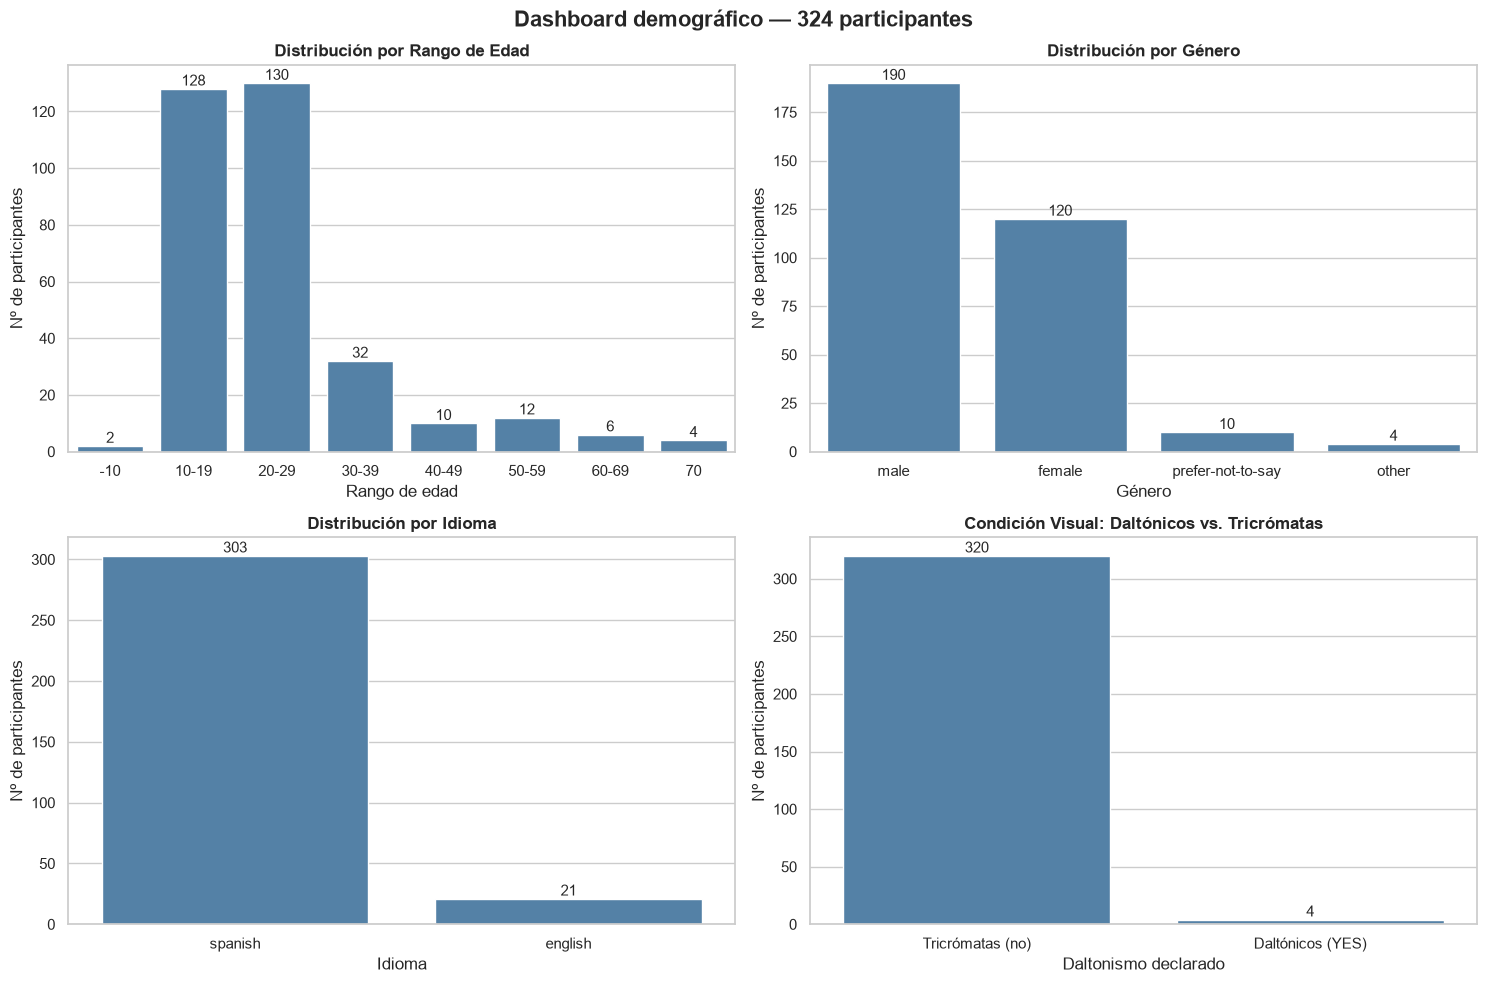

In [13]:
# TODO 5.1: Crear el Dashboard Demográfico (2x2 subplots)
orden_edad = ['-10', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70']
orden_edad = [e for e in orden_edad if e in df_usuarios['ageRange'].astype(str).unique()]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

paneles = [
    (axes[0, 0], 'ageRange', 'Distribución por Rango de Edad', 'Rango de edad', orden_edad),
    (axes[0, 1], 'gender', 'Distribución por Género', 'Género',
     df_usuarios['gender'].value_counts().index),
    (axes[1, 0], 'language', 'Distribución por Idioma', 'Idioma',
     df_usuarios['language'].value_counts().index),
    (axes[1, 1], 'colorblind', 'Condición Visual: Daltónicos vs. Tricrómatas', 'Daltonismo declarado',
     ['no', 'YES']),
]

for ax, col, titulo, xlabel, orden in paneles:
    sns.countplot(data=df_usuarios.astype({col: str}), x=col, order=orden, ax=ax, color='steelblue')
    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Nº de participantes')
    for cont in ax.containers:
        ax.bar_label(cont)

axes[1, 1].set_xticks(range(2))
axes[1, 1].set_xticklabels(['Tricrómatas (no)', 'Daltónicos (YES)'])

fig.suptitle(f'Dashboard demográfico — {len(df_usuarios)} participantes', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.2 Gráfico 2: Comparativa Visual: Percepción de Tricrómatas vs. Daltónicos
Elige dos palabras con discrepancia evidente (por ejemplo, `'ZAFIRO'` y `'JADE'`).

Crea una figura con 2 subplots (`1x2`):
- **Panel Izquierdo (`ZAFIRO`):** Gráfico de barras (`sns.countplot` o `.value_counts().plot(kind='bar')`) comparando los colores elegidos por tricrómatas frente a daltónicos.
- **Panel Derecho (`JADE`):** Gráfico de barras análogo para la palabra `JADE`.

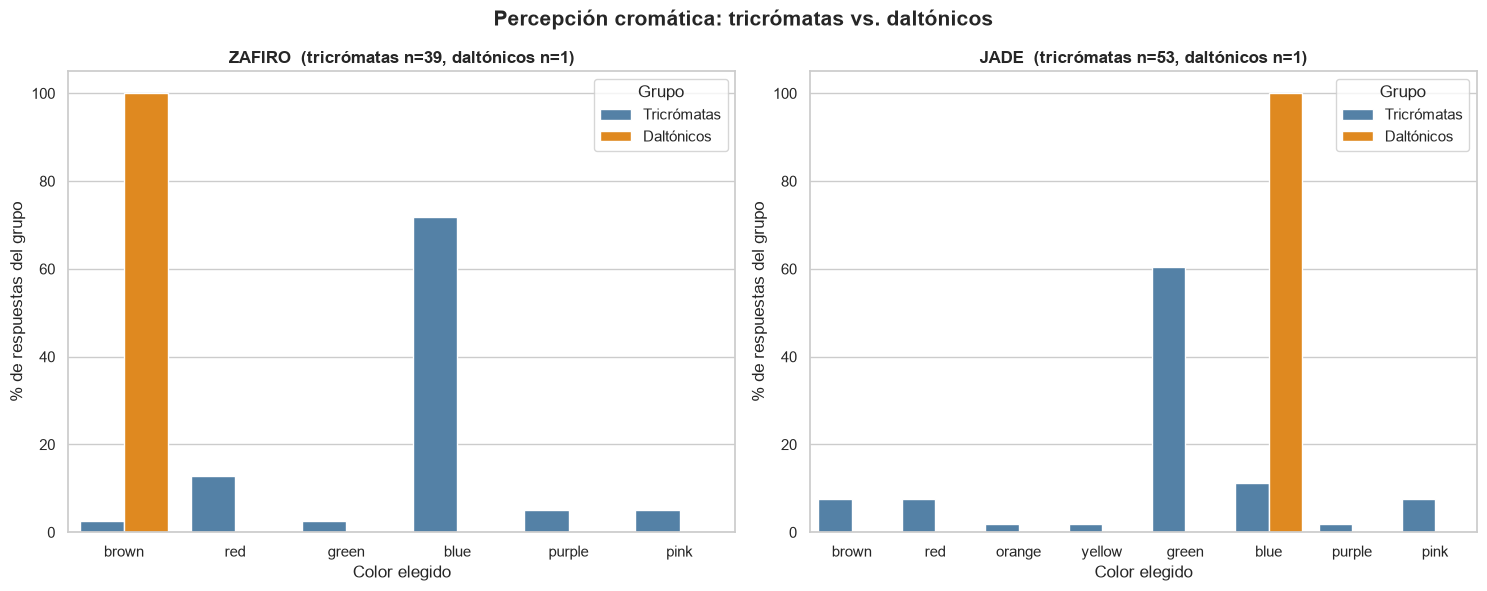

In [14]:
# TODO 5.2: Gráfico comparativo de percepción cromática en palabras críticas
# Se reutilizan paleta_colores y orden_colores (definidos tras la Fase 1.4)

def comparativa_grupos(palabra, ax):
    """Barras con el % de elección de cada color para tricrómatas vs. daltónicos en una palabra."""
    tri = df_tricromatas.loc[df_tricromatas['word'] == palabra, 'color'].value_counts(normalize=True) * 100
    dal = df_daltonicos.loc[df_daltonicos['word'] == palabra, 'color'].value_counts(normalize=True) * 100
    datos = (pd.DataFrame({'Tricrómatas': tri, 'Daltónicos': dal})
             .reindex(orden_colores).fillna(0)
             .rename_axis('color').reset_index()
             .melt(id_vars='color', var_name='Grupo', value_name='porcentaje'))
    datos = datos[datos.groupby('color')['porcentaje'].transform('sum') > 0]
    sns.barplot(data=datos, x='color', y='porcentaje', hue='Grupo',
                palette={'Tricrómatas': 'steelblue', 'Daltónicos': 'darkorange'}, ax=ax)
    n_tri = (df_tricromatas['word'] == palabra).sum()
    n_dal = (df_daltonicos['word'] == palabra).sum()
    ax.set_title(f'{palabra}  (tricrómatas n={n_tri}, daltónicos n={n_dal})', fontweight='bold')
    ax.set_xlabel('Color elegido')
    ax.set_ylabel('% de respuestas del grupo')
    ax.set_ylim(0, 105)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
comparativa_grupos('ZAFIRO', axes[0])
comparativa_grupos('JADE', axes[1])
fig.suptitle('Percepción cromática: tricrómatas vs. daltónicos', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.3 Gráfico 3: Visualización del Fenómeno de las Anclas Culturales
Crea una figura con 2 subplots (`1x2`):
- **Panel Izquierdo:** Gráfico de barras con la distribución de colores para `'TRACTOR'` en `df_tricromatas`, destacando el color dominante (`yellow`).
- **Panel Derecho:** Gráfico de barras con la distribución de colores para `'ESPERANZA'`, destacando el color dominante (`green`).

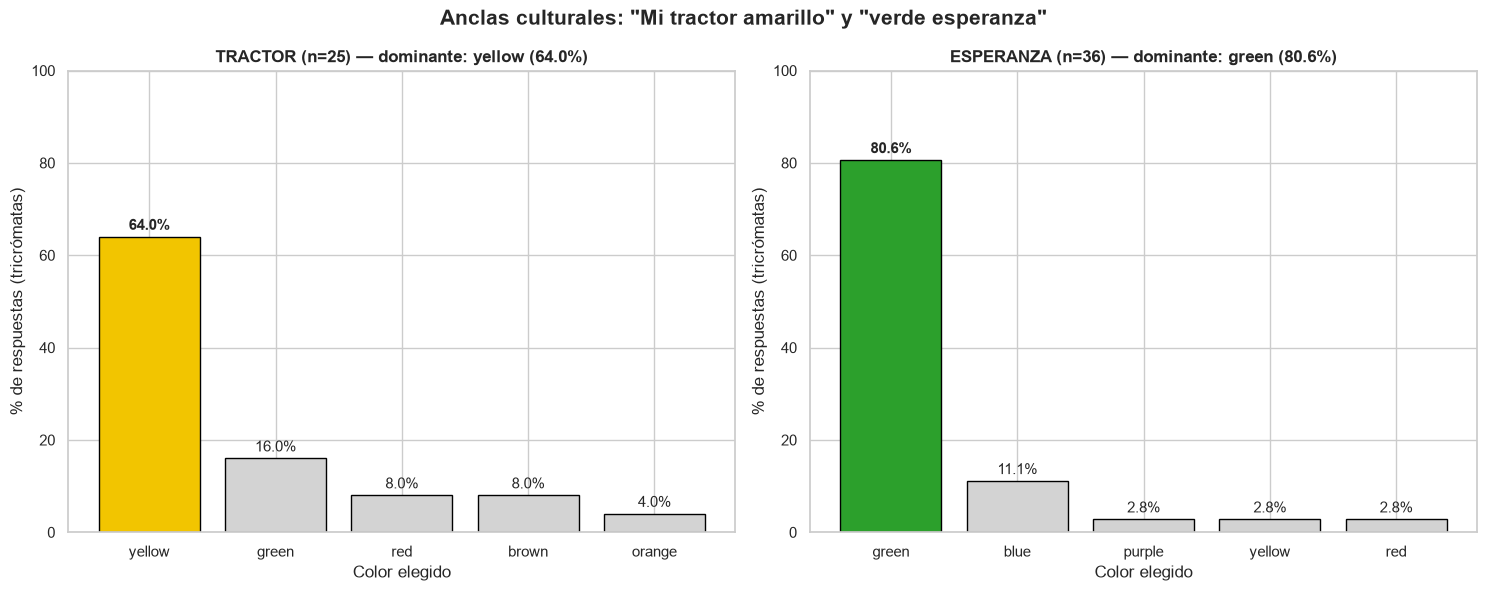

In [15]:
# TODO 5.3: Visualización de las Anclas Culturales (TRACTOR y ESPERANZA)
def grafico_ancla(palabra, ax):
    """Barras de % por color para una palabra, resaltando el color dominante."""
    dist = distribucion_colores(df_tricromatas, palabra)
    dominante = dist.index[0]
    colores_barras = [paleta_colores[c] if c == dominante else 'lightgray' for c in dist.index]
    ax.bar(dist.index, dist.values, color=colores_barras, edgecolor='black')
    for x, v in zip(dist.index, dist.values):
        ax.text(x, v + 1.5, f'{v:.1f}%', ha='center', fontweight='bold' if x == dominante else 'normal')
    n = (df_tricromatas['word'] == palabra).sum()
    ax.set_title(f'{palabra} (n={n}) — dominante: {dominante} ({dist.iloc[0]:.1f}%)', fontweight='bold')
    ax.set_xlabel('Color elegido')
    ax.set_ylabel('% de respuestas (tricrómatas)')
    ax.set_ylim(0, 100)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
grafico_ancla('TRACTOR', axes[0])
grafico_ancla('ESPERANZA', axes[1])
fig.suptitle('Anclas culturales: "Mi tractor amarillo" y "verde esperanza"', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.4 Gráfico 4: Ranking de Consenso Semántico por Categoría
Crea un gráfico de barras horizontal (`sns.barplot` con orientación horizontal `x='consenso', y='clueCategory'`) que muestre el consenso medio de color para cada una de las categorías semánticas, ordenado de mayor a menor acuerdo.

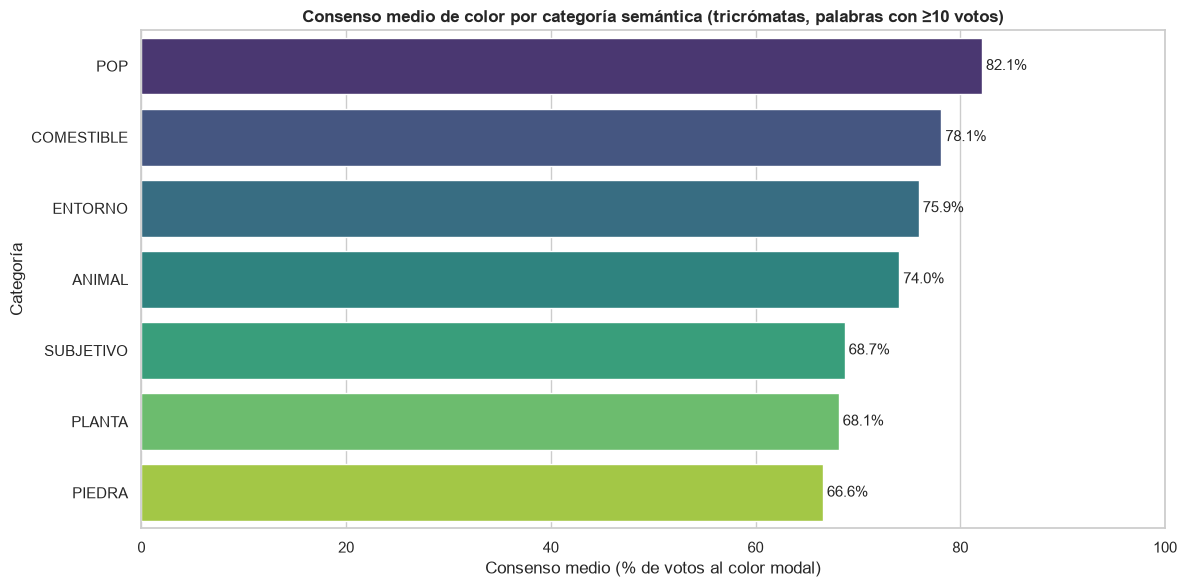

In [16]:
# TODO 5.4: Gráfico de barras horizontal del consenso semántico por categoría
df_consenso_cat = consenso_categoria.reset_index()  # columnas: clueCategory, consenso

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=df_consenso_cat, x='consenso', y='clueCategory',
            order=df_consenso_cat['clueCategory'], hue='clueCategory', legend=False,
            palette='viridis', ax=ax)
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.1f%%', padding=3)
ax.set_title(f'Consenso medio de color por categoría semántica (tricrómatas, palabras con ≥{MIN_VOTOS} votos)',
             fontweight='bold')
ax.set_xlabel('Consenso medio (% de votos al color modal)')
ax.set_ylabel('Categoría')
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### 5.5 Gráfico 5: Mapa de Elecciones sobre el Tablero
El tablero tiene 480 casillas (filas `A`–`P` × columnas `1`–`30`). Cada casilla se pinta con el color de su categoría y encima se dibuja un círculo cuyo tamaño es proporcional al número de veces que fue elegida.

- **Mapa global:** todas las respuestas de los tricrómatas, para ver qué zonas del tablero concentran las elecciones.
- **Mapa por palabra:** dónde marcó cada grupo (tricrómatas ● vs. daltónicos ✖) para las anclas culturales y las palabras críticas.

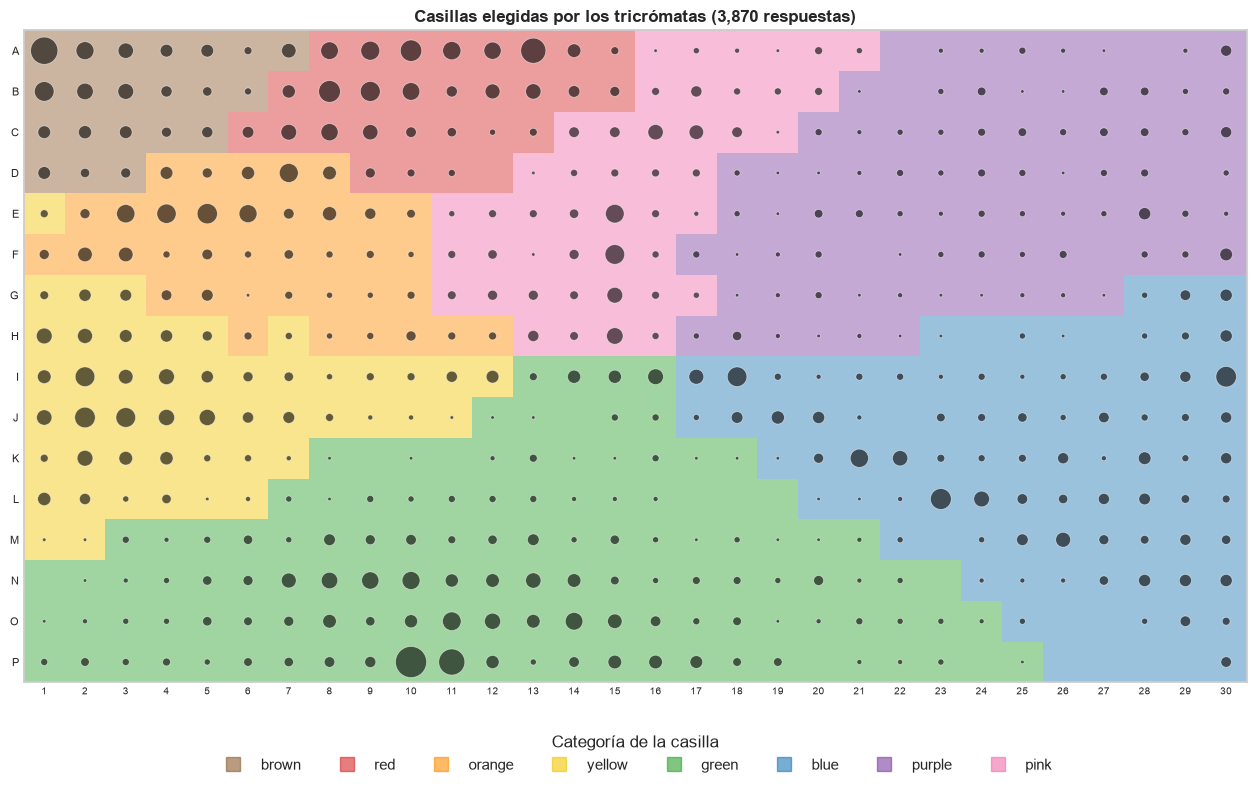

Casillas más elegidas:


coordinate,veces,color
P10,78,green
A1,60,brown
P11,55,green
A13,51,red
B8,38,red
A10,37,red
L23,35,blue
J2,34,yellow
I30,34,blue
E5,33,orange


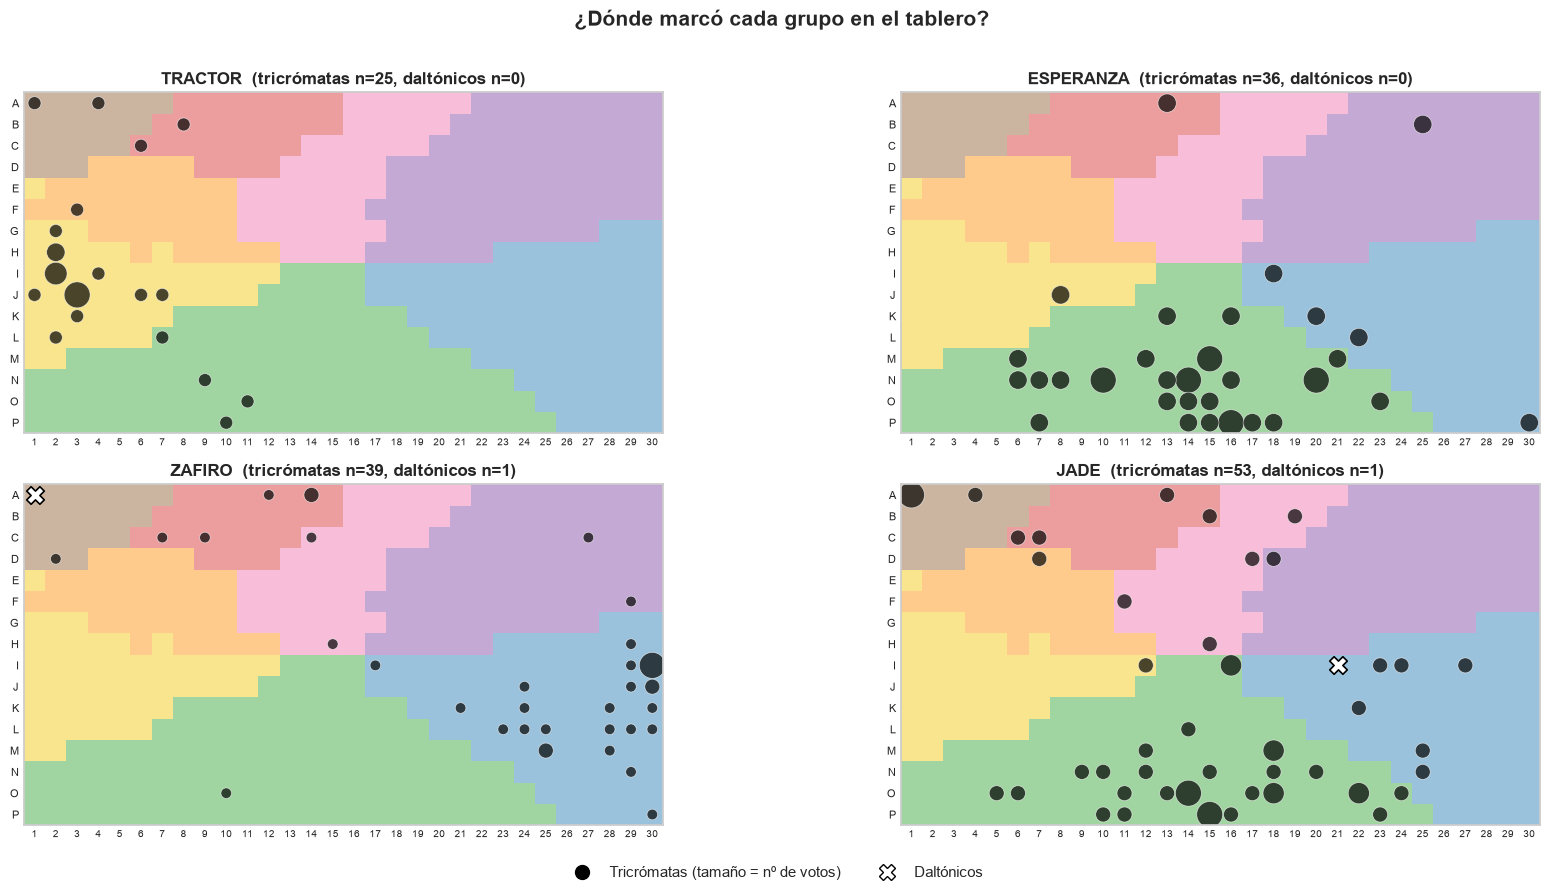

In [17]:
# Gráfico 5.5: Mapa de elecciones sobre el tablero
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

filas_tablero = sorted(df_tablero['coordinate'].str[0].unique())        # 'A' ... 'P'
n_filas = len(filas_tablero)
n_cols = df_tablero['coordinate'].str[1:].astype(int).max()             # 30
indice_fila = {f: i for i, f in enumerate(filas_tablero)}


def coord_a_xy(coords):
    """Convierte coordenadas tipo 'E11' en (columna, fila) numéricas."""
    return coords.str[1:].astype(int), coords.str[0].map(indice_fila)


# Imagen RGB del tablero con el color de categoría de cada casilla
tablero_rgb = np.ones((n_filas, n_cols, 3))
for x, y, c in zip(*coord_a_xy(df_tablero['coordinate']), df_tablero['color']):
    tablero_rgb[y, x - 1] = to_rgb(paleta_colores[c])


def dibujar_tablero(ax, titulo):
    """Fondo del tablero con los colores de categoría atenuados."""
    ax.imshow(tablero_rgb, alpha=0.45, aspect='equal',
              extent=(0.5, n_cols + 0.5, n_filas - 0.5, -0.5))
    ax.set_xticks(range(1, n_cols + 1))
    ax.set_xticklabels(range(1, n_cols + 1), fontsize=7)
    ax.set_yticks(range(n_filas))
    ax.set_yticklabels(filas_tablero, fontsize=8)
    ax.tick_params(length=0)
    ax.grid(False)
    ax.set_title(titulo, fontweight='bold')


def dibujar_elecciones(ax, df, tam_max=400, **estilo):
    """Círculos con área proporcional a las veces que se eligió cada casilla."""
    conteo = df['coordinate'].value_counts()
    x, y = coord_a_xy(conteo.index.to_series())
    ax.scatter(x, y, s=conteo.values / conteo.max() * tam_max, **estilo)
    return conteo


# Mapa global: todas las respuestas tricrómatas
fig, ax = plt.subplots(figsize=(16, 8))
dibujar_tablero(ax, f'Casillas elegidas por los tricrómatas ({len(df_tricromatas):,} respuestas)')
conteo_global = dibujar_elecciones(ax, df_tricromatas, tam_max=500,
                                   color='black', alpha=0.6, edgecolor='white', linewidth=0.5)
ax.legend(handles=[Line2D([], [], marker='s', ls='', ms=10, color=paleta_colores[c], alpha=0.6, label=c)
                   for c in orden_colores],
          title='Categoría de la casilla', loc='upper center', bbox_to_anchor=(0.5, -0.06),
          ncol=len(orden_colores), frameon=False)
plt.tight_layout()
plt.show()

print("Casillas más elegidas:")
display(conteo_global.head(10).rename_axis('coordinate').reset_index(name='veces')
        .assign(color=lambda d: d['coordinate'].map(coord_a_color))
        .style.map(pintar_color, subset=['color'])
        .bar(subset=['veces'], color='#bbbbbb').hide(axis='index'))

# Mapa por palabra: tricrómatas vs. daltónicos
palabras_mapa = ['TRACTOR', 'ESPERANZA', 'ZAFIRO', 'JADE']
fig, axes = plt.subplots(2, 2, figsize=(18, 9))
for palabra, ax in zip(palabras_mapa, axes.flat):
    tri = df_tricromatas[df_tricromatas['word'] == palabra]
    dal = df_daltonicos[df_daltonicos['word'] == palabra]
    dibujar_tablero(ax, f'{palabra}  (tricrómatas n={len(tri)}, daltónicos n={len(dal)})')
    dibujar_elecciones(ax, tri, tam_max=350, color='black', alpha=0.7, edgecolor='white', linewidth=0.5)
    if not dal.empty:
        x, y = coord_a_xy(dal['coordinate'])
        ax.scatter(x, y, marker='X', s=160, color='white', edgecolor='black', linewidth=1.2, zorder=3)
fig.legend(handles=[Line2D([], [], marker='o', ls='', ms=10, color='black', label='Tricrómatas (tamaño = nº de votos)'),
                    Line2D([], [], marker='X', ls='', ms=11, markerfacecolor='white', markeredgecolor='black',
                           label='Daltónicos')],
           loc='lower center', ncol=2, frameon=False, fontsize=11)
fig.suptitle('¿Dónde marcó cada grupo en el tablero?', fontsize=15, fontweight='bold')
plt.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.show()

---
## 💡 Fase 6: Extracción de Conclusiones y Discusión Crítica

> ✍️ **Preguntas de Reflexión para el Alumno:**
>
> 1. **Calidad de Datos y Validez Perceptual:** ¿Por qué en estudios psicofísicos y de percepción visual es imprescindible filtrar y aislar a los participantes con deficiencias visuales (como el daltonismo) antes de calcular la verdad de referencia (*ground truth*)?
>
> 2. **Patrón de Confusión Cromática:** Observando las palabras analizadas (*ZAFIRO*, *JADE*, *BLAS*), ¿qué tipo de confusión cromática se manifiesta en las personas daltónicas? ¿En qué casos coinciden plenamente con los tricrómatas?
>
> 3. **Influencia del Lenguaje y la Cultura:** ¿Qué nos demuestra el caso de *TRACTOR* y *ESPERANZA* sobre la cognición humana? ¿La memoria del color es puramente física o está modulada por la cultura popular y el lenguaje materno?
>
> 4. **Consenso entre Categorías:** ¿Por qué categorías como *COMESTIBLE* o *ANIMAL* tienen mayor consenso que *SUBJETIVO* o *PIEDRA*?

### ✍️ Respuestas a las preguntas de reflexión

**1. Calidad de datos y validez perceptual.**

La idea del estudio es sacar una "respuesta de referencia" para cada palabra, o sea, el color que elige la mayoría de la gente con visión normal. Si se mezclan las respuestas de las personas con daltonismo, sus respuestas pueden ser distintas simplemente porque ven los colores de otra forma, y eso podría cambiar el color más votado o bajar el porcentaje de acuerdo. Por eso las he separado. No es que sus respuestas estén "mal", es que miden otra cosa.

De las 3.899 respuestas, 3.870 están marcadas con «no» y solo 29 con «YES». Me llamó la atención que hay 8 usuarios que tienen las dos etiquetas en respuestas distintas, por eso salen 323 usuarios en un grupo y 9 en el otro (más de los 324 que hay en total). Como he filtrado por respuesta y no por usuario, algunas personas acaban en los dos grupos. Esto me enseñó que no basta con mirar si hay valores nulos: también hay que comprobar si los datos tienen sentido.

**2. Diferencias en la elección de colores.**

De las ocho palabras que he comparado, en tres el grupo daltónico coincide con el color más votado por los tricrómatas: CIELO (azul), BARBIE (rosa) y MENTA (verde). En las otras cinco no coincide: en ZAFIRO eligieron marrón en vez de azul, en JADE azul en vez de verde, en BLAS (Y EPI) rojo en vez de amarillo, en HURACÁN rosa en vez de azul y en MALVA marrón (aquí los tricrómatas tampoco se ponen de acuerdo, porque hay empate entre rosa y morado).

Se ven confusiones del tipo verde–azul o azul–marrón, pero no sale claramente el patrón típico rojo–verde del que se suele hablar. Y hay que tener mucho cuidado: cada una de estas palabras tiene **una sola respuesta** del grupo daltónico, y tres de las cinco diferencias (ZAFIRO, MALVA y HURACÁN) son de la misma persona. Con tan pocos datos, y con las etiquetas que no cuadran, no se puede decir que haya un patrón general ni que las diferencias se deban solo al daltonismo.

**3. Influencia del lenguaje y la cultura.**

En TRACTOR, el 64 % de los tricrómatas eligió amarillo, y solo un 16 % verde y un 8 % rojo, que serían los colores más habituales de los tractores de verdad. Parece bastante claro que influye la canción «Mi tractor amarillo». En ESPERANZA, que no tiene color físico, el 80,6 % eligió verde, que cuadra con la expresión «verde esperanza».

Esto me hace pensar que, cuando asociamos una palabra con un color, no solo tiramos de lo que hemos visto, sino también de canciones, expresiones y cosas de nuestra cultura. Eso sí, con estos datos no puedo demostrar que la canción o la expresión sean la causa. Además, las muestras son pequeñas (25 respuestas para TRACTOR y 36 para ESPERANZA) y 303 de los 324 participantes tienen el español como idioma, así que no sé si en otro país o idioma saldría lo mismo.

**4. Consenso entre categorías.**

Contando solo las palabras con al menos 10 votos, la categoría con más acuerdo es POP (82,1 %), seguida de COMESTIBLE (78,1 %), ENTORNO (75,9 %) y ANIMAL (74,0 %). Las que tienen menos acuerdo son SUBJETIVO (68,7 %), PLANTA (68,1 %) y PIEDRA (66,6 %). Ojo, este porcentaje mide el acuerdo en el color general (verde, azul…), no en la casilla exacta del tablero.

Tiene sentido: muchos personajes y alimentos tienen un color muy concreto que todo el mundo conoce (BARBIE es rosa, PEPINO es verde). En cambio, las palabras subjetivas dependen más de lo que cada uno siente o imagina, y las plantas y piedras pueden tener muchos colores distintos según cuál te venga a la cabeza. Aun así, las diferencias entre categorías no son enormes (entre un 67 % y un 82 %).

Puse el mínimo de 10 votos porque si una palabra tiene un solo voto, su consenso sale del 100 %, aunque eso no signifique nada. Con este filtro me quedo con 100 de las 177 palabras, así que las medias hablan de esas palabras y no de todas.